In [126]:
from dotenv import load_dotenv
import os

In [127]:
load_dotenv()

True

In [128]:
from langchain_openai import AzureChatOpenAI

llm = AzureChatOpenAI(
    api_key = os.getenv("AZURE_OPENAI_API_KEY"),
    api_version=os.getenv("AZURE_OPENAI_API_VERSION"),
    azure_deployment = os.getenv("AZURE_OPENAI_DEPLOYMENT_NAME"),
    azure_endpoint= os.getenv("AZURE_OPENAI_ENDPOINT"),
)

In [129]:
llm.invoke("Hello")

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 18, 'prompt_tokens': 7, 'total_tokens': 25, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}, 'latency_checkpoint': {'engine_tbt_ms': 0, 'engine_ttft_ms': 314, 'engine_ttlt_ms': 315, 'pre_inference_ms': 67, 'service_tbt_ms': 2, 'service_ttft_ms': 471, 'service_ttlt_ms': 505, 'user_visible_ttft_ms': 404}}, 'model_provider': 'openai', 'model_name': 'gpt-5.1-2025-11-13', 'system_fingerprint': None, 'id': 'chatcmpl-ESUwj7029L5HSzidEeL4HsCMX3cId', 'service_tier': 'default', 'prompt_filter_results': [{'prompt_index': 0, 'content_filter_results': {'hate': {'filtered': False, 'severity': 'safe'}, 'jailbreak': {'detected': False, 'filtered': False}, 'self_harm': {'filter

In [130]:
from typing_extensions import TypedDict
from typing import Literal
from pydantic import BaseModel

class Supervisor(TypedDict):
    step: Literal["technical","comparison","general_research"]

class ResearchPlan(BaseModel):
    tasks: list[str]

# Critic
class CriticDecision(BaseModel):
    sufficient: bool
    feedback: str

In [131]:
router_model = llm.with_structured_output(Supervisor)
research_plan = llm.with_structured_output(ResearchPlan)
critic_model = llm.with_structured_output(CriticDecision)

In [132]:
router_model.invoke("Choose one topic")

{'step': 'general_research'}

In [133]:
from typing import Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

class OverallState(TypedDict):
    question: str
    type: str
    completed: Annotated[list[AnyMessage], add_messages]
    iteration: int
    tasks: list[str]
    critic_feedback: str
    critic_sufficient: bool
    result: str

In [134]:
class Workerstate(TypedDict):
    question: str
    task: str
    completed: Annotated[list[AnyMessage], add_messages]


In [135]:
def classification(state: OverallState):
    if state["type"] == "comparison":
        return "comparison"
    elif state["type"] == "general_research":
        return "general_research"
    elif state["type"] == "technical":
        return "technical"

In [136]:
from langchain_core.messages import HumanMessage, SystemMessage

def planner(state: OverallState):
    plan = research_plan.invoke([
        SystemMessage(content="""
            Generate a research plan for the user's question.

            Break the question into multiple specific research tasks.
            Return only the tasks as a Python-style list of strings.
            """),
        HumanMessage(content=f"""Here is the question {state['question']} and here is the previous critic feedback {state.get('critic_feedback', '')}""")
    ])

    return {
        "tasks": plan.tasks,
        "iteration": state.get("iteration", 0) + 1
        }

In [137]:
def worker(state: Workerstate):

    msg = llm.invoke([
        SystemMessage(content="""
            You are a research worker.

            Your job is to investigate ONLY the research task
            assigned to you.

            Provide factual, detailed findings that another
            agent can later use to synthesize the final answer.

            Do not try to answer unrelated parts of the question.
        """),

        HumanMessage(
            content=f"""
            Original research question:
            {state['question']}

            Your assigned research task:
            {state['task']}
            """
        )
    ])

    return {
        "completed": [HumanMessage(content=f"""Research task:{state['task']} Research findings: {msg.content}""")]}

In [138]:
from langgraph.types import Send
def assign_worker(state: OverallState):
    """ Assign node to each worker"""
    return[
        Send("worker", {"question": state["question"], "task": s}) for s in state['tasks']
    ]

In [139]:
def supervisor(state: OverallState):

    decision = router_model.invoke([
        SystemMessage(content="""
            You are a research supervisor.

            Classify the user's research question into exactly
            one of these categories:

            technical:
                Questions primarily about technical concepts,
                implementation, architecture, programming,
                systems, or engineering.

            comparison:
                Questions that explicitly compare two or more
                technologies, approaches, products, or concepts.

            general_research:
                General research questions that do not primarily
                fall into the technical or comparison categories.
        """),

        HumanMessage(
            content=f"Research question: {state['question']}"
        )
    ])

    return {"type": decision["step"]}

In [140]:
def critic(state: OverallState):

    research = "\n\n".join(message.content for message in state["completed"])

    decision = critic_model.invoke([
        SystemMessage(content="""
            You are a research critic.

            Evaluate whether the collected research is sufficient
            to answer the original research question thoroughly.

            Identify important missing information.

            Return:
            - sufficient=True if the research is adequate
            - sufficient=False if more research is needed

            If more research is needed, explain exactly what
            information is missing.
        """),

        HumanMessage(content=f"""Original question: {state['question']} Research collected so far: {research}""")
    ])

    return {
        "critic_sufficient": decision.sufficient,
        "critic_feedback": decision.feedback
    }

In [141]:
def critic_router(state: OverallState):

    if state["critic_sufficient"]:
        return "synthesizer"

    if state["iteration"] >= 3:
        return "synthesizer"

    return "planner"

In [142]:
def synthesizer(state: OverallState):

    research = "\n\n".join(message.content for message in state["completed"])

    response = llm.invoke([
        SystemMessage(content="""
            You are the final research synthesizer.

            Answer the user's original question using the research
            collected by the research workers.

            Combine the findings into one coherent answer.

            Do not mention the internal workers, planner, critic,
            or graph.

            Where appropriate, organize the answer using headings,
            bullet points, tables, and a clear conclusion.
        """),

        HumanMessage(content=f"""Original question: {state['question']} Research findings: {research}""")
    ])

    return {
        "result": response.content
    }

In [143]:
from langgraph.graph import StateGraph, START, END


builder = StateGraph(OverallState)

builder.add_node("supervisor", supervisor)
builder.add_node("planner", planner)
builder.add_node("worker", worker)
builder.add_node("critic", critic)
builder.add_node("synthesizer", synthesizer)

builder.add_edge(START, "supervisor")

builder.add_conditional_edges(
    "supervisor",
    classification,
    {
        "technical": "planner",
        "comparison": "planner",
        "general_research": "planner"
    }
)

builder.add_conditional_edges(
    "planner",
    assign_worker,
    ["worker"]
)

builder.add_edge("worker", "critic")

builder.add_conditional_edges(
    "critic",
    critic_router,
    {
        "planner": "planner",
        "synthesizer": "synthesizer"
    }
)

builder.add_edge("synthesizer", END)


graph = builder.compile()

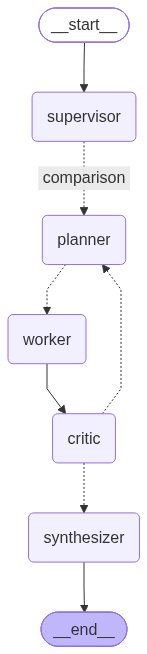

In [144]:
from IPython.display import display, Image

display(Image(graph.get_graph().draw_mermaid_png()))

In [145]:
question = """
Compare FastAPI, Flask, and Django for building and deploying
a machine learning inference API.

Consider performance, scalability, asynchronous support,
ease of development, deployment options, and integration
with machine learning libraries.

Provide a final recommendation based on the findings.
"""

In [146]:
initial_state = {
    "question": question,
    "type": "",
    "tasks": [],
    "completed": [],
    "result": "",
    "iteration": 0,
    "critic_sufficient": False,
    "critic_feedback": ""
}

In [147]:
output = graph.invoke(initial_state)

c:\Users\jehoo\AppData\Local\anaconda3\envs\all_env\Lib\site-packages\pydantic\main.py:464: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=ResearchPlan(tasks=['Clar...or ML inference APIs.']), input_type=ResearchPlan])
  return self.__pydantic_serializer__.to_python(
c:\Users\jehoo\AppData\Local\anaconda3\envs\all_env\Lib\site-packages\pydantic\main.py:464: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=CriticDecision(sufficient...l question thoroughly.'), input_type=CriticDecision])
  return self.__pydantic_serializer__.to_python(
c:\Users\jehoo\AppData\Local\anaconda3\envs\all_env\Lib\site-packages\pydantic\main.py:464: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value

In [150]:
from pprint import pprint

for message in output["result"]:
    print(message.pretty_print())

AttributeError: 'str' object has no attribute 'pretty_print'